# Spotify Tracks - Evaluación Parcial N°2

**MLY1101, Caso C. Equipo: Benjamín Palomino, Benjamín Díaz y Freymuth Christopher Isaac.**

Continuamos la experiencia 1 y ejecutamos CRISP-DM completo: negocio, datos, preparación, modelos supervisados, segmentación y evaluación. Este cuaderno parte del CSV original, vuelve a entrenar y guarda evidencia. Usa **Restart Kernel and Run All Cells**. Instala `requirements.txt` desde terminal antes de ejecutarlo. Los scripts importados contienen la implementación y sus comentarios.

La pregunta es cuánta señal aportan audio y género para estimar popularidad **observada**. No tenemos fechas para pronosticar popularidad futura ni datos de campañas para medir ROI. Metas técnicas previas: MAE <=15 y mejora >=10% frente a la media. Los perfiles musicales apoyarán exploración humana, sin decisiones automáticas sobre artistas.

In [1]:
from pathlib import Path
import sys, json, time
from IPython.display import display, Markdown, Image
import pandas as pd

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/raw/Spotify_Tracks_Dataset.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Abre el notebook dentro del proyecto completo con data/raw y src.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.eva2.data import prepare
from src.eva2.supervised import fit_supervised
from src.eva2.clustering import fit_clustering
from src.eva2.sensitivity import audit_genre, audit_label_policy
from src.eva2.plots import make_plots
from src.eva2.reporting import build_reports
from src.eva2.predict import predict
from src.features.prepare_features import MODEL_FEATURES
start = time.perf_counter()
print('Proyecto localizado: data/raw y src disponibles')
print('Python:', sys.version.split()[0])

Proyecto localizado: data/raw y src disponibles
Python: 3.14.4


## 1. Datos, calidad y preparación

Verificamos el hash del archivo recibido y reutilizamos la limpieza de experiencia 1. El descarte por duración es una decisión heredada y puede excluir piezas válidas. Un ID puede aparecer en varios géneros y la regla conserva su primera etiqueta, una limitación del conjunto preparado.

La separación usa grupos de audio exactamente igual, para que versiones de distinta ID no crucen conjuntos. Se estratifican los grupos según deciles de su popularidad mediana, con 80/20 de grupos. No se ajusta ningún escalador antes de separar. El objetivo solo interviene en estratificación, nunca en la huella o en los predictores.

In [2]:
data = prepare(ROOT)
display(pd.Series(data['audit'], name='valor').to_frame())
display(pd.read_csv(ROOT / 'reports/eva2/cleaning.csv'))
display(data['clean'].describe(include='number').T)
assert data['audit']['shared_tracks'] == 0
assert data['audit']['shared_audio_groups'] == 0
assert data['audit']['clean_missing_cells'] == 0

,valor
sha256,335e5ee0a07a3f30b20ca9860c87562c98082a032e0ecd...
raw_rows,114000
raw_columns,21
raw_missing_cells,3
raw_unique_tracks,89741
clean_rows,89495
raw_retention_pct,78.504386
unique_retention_pct,99.725878
clean_missing_cells,0
clean_genres,113


,paso,filas_antes,filas_despues,filas_eliminadas
0,Eliminar columna de indice exportado,114000,114000,0
1,"Eliminar registros sin artista, album o cancion",114000,113999,1
2,Conservar un registro por track_id,113999,89740,24259
3,Conservar duraciones entre 30 segundos y 20 mi...,89740,89653,87
4,Eliminar tempo o compas no validos,89653,89495,158
5,Validar caracteristicas de audio entre 0 y 1,89495,89495,0


,count,mean,std,min,25%,50%,75%,max
popularity,89495.0,33.202961,20.592685,0.00000,19.0000,33.000000,49.00000,100.000
duration_ms,89495.0,227677.538656,90970.338789,30080.00000,173142.5000,213333.000000,264208.50000,1194057.000
explicit,89495.0,0.086061,0.280455,0.00000,0.0000,0.000000,0.00000,1.000
danceability,89495.0,0.563277,0.175177,0.05130,0.4510,0.577000,0.69200,0.985
energy,89495.0,0.635509,0.255622,0.00002,0.4590,0.677000,0.85300,1.000
key,89495.0,5.283893,3.559305,0.00000,2.0000,5.000000,8.00000,11.000
loudness,89495.0,-8.470227,5.173641,-46.59100,-10.2990,-7.174000,-5.10200,4.532
mode,89495.0,0.636896,0.480897,0.00000,0.0000,1.000000,1.00000,1.000
speechiness,89495.0,0.087583,0.113288,0.02210,0.0360,0.049000,0.08600,0.965
acousticness,89495.0,0.327792,0.337993,0.00000,0.0171,0.187000,0.62400,0.996


In [3]:
# EDA: relaciones descriptivas, no causales.
display(pd.read_csv(ROOT / 'reports/eva2/genres.csv').sort_values('mean', ascending=False).head(10))
display(pd.read_csv(ROOT / 'reports/eva2/explicit.csv'))
display(pd.read_csv(ROOT / 'reports/eva2/correlations.csv', index_col=0)['popularity'].sort_values())

,track_genre,count,mean,median,std
65,k-pop,912,59.471491,61.0,12.240154
81,pop-film,815,59.096933,60.0,10.736133
71,metal,232,56.422414,63.0,19.012482
15,chill,972,53.738683,57.0,14.822521
68,latino,398,51.788945,46.0,26.055660
94,sad,564,51.109929,52.0,12.082839
44,grunge,862,50.587007,54.0,14.456992
55,indian,733,49.765348,49.0,11.664225
5,anime,995,48.776884,50.0,11.715888
33,emo,932,48.500000,50.0,16.966480


,explicit,count,mean,median
0,0,81793,32.855477,33.0
1,1,7702,36.893145,37.0


instrumentalness   -0.128075
speechiness        -0.046764
acousticness       -0.038791
duration_ms        -0.020960
liveness           -0.014349
valence            -0.011582
tempo               0.008740
energy              0.014010
danceability        0.065514
loudness            0.072543
popularity          1.000000
Name: popularity, dtype: float64

### Auditoría de etiquetas y criterio de referencia

No suponemos que duplicados del mismo ID tengan siempre idéntica popularidad. La auditoría cuantifica primera fila, mediana y rango. Se conserva la primera observación por continuidad y falta de fecha autoritativa. Esto define una referencia reproducible, sin convertirla en verdad temporal. En la sección 4 mediremos sensibilidad a entrenar con mediana usando solo train, sin cambiar el target de test ni seleccionar una regla por su score.

In [4]:
display(json.loads((ROOT / 'reports/eva2/target_audit.json').read_text(encoding='utf-8')))
display(pd.read_csv(ROOT / 'reports/eva2/target_conflicts.csv')
        .sort_values('range', ascending=False).head(10))

{'policy': 'first_observed_row_by_track_id',
 'policy_changes_primary_target': False,
 'justification': 'Continuidad y definición reproducible de la referencia. Sin fecha ni fuente autoritativa no se infiere que máximo, última fila o mediana sea el valor verdadero. Se reporta sensibilidad solo en entrenamiento.',
 'conflicting_ids_raw': 720,
 'conflicting_ids_pct': 0.8023088666272941,
 'conflicting_ids_retained': 720,
 'median_range': 1.0,
 'maximum_range': 44.0,
 'range_greater_than_20': 10,
 'first_differs_from_median_retained': 517,
 'multi_genre_ids': 16299,
 'sensitivity_scope': 'mismos tres folds del entrenamiento; validación contra referencia first; test sin alterar'}

,track_id,first,median,min,max,size,nunique,range,genre_count,retained,retained_target,retained_genre,split,first_minus_median
535,5hljqZrl0h7RcIhUnOPuve,0,0.0,0,44,3,2,44,3,True,0,garage,train,0.0
139,1UwUhKmFxGKs59xiWO60Sx,0,0.0,0,42,3,2,42,3,True,0,garage,train,0.0
15,0C6dSPCqwKqwos6s1CrDrh,0,0.0,0,42,3,2,42,3,True,0,garage,train,0.0
554,5ygEUpyZy5qtZ1423zymBW,0,0.0,0,41,3,2,41,3,True,0,garage,train,0.0
187,1zx6GSqLYI2ynzAHnPRKBR,0,0.0,0,41,3,2,41,3,True,0,garage,train,0.0
401,4KPi4VNvPOfKqIp1sx19Xf,0,0.0,0,41,3,2,41,3,True,0,garage,train,0.0
530,5fClRRa7P9nPIpstj50veV,0,0.0,0,40,3,2,40,3,True,0,garage,train,0.0
93,0z5x3VmmQ7cyTeOP7VAf3T,0,0.0,0,40,3,2,40,3,True,0,garage,train,0.0
371,42GuKw49pPxNAkIhWGwgFs,0,0.0,0,39,3,2,39,3,True,0,garage,train,0.0
13,0BhLfxWA4TwGu8bGVKBotN,0,13.5,0,27,2,2,27,2,True,0,progressive-house,test,-13.5


## 2. Modelos supervisados

Es una regresión: `popularity` es numérica entre 0 y 100. Comparamos referencias de media y mediana, regresión lineal, árbol de decisión y un ensamble HistGradientBoosting. Los dos primeros algoritmos aprendidos en clase cubren el mínimo supervisado y el ensamble amplía la comparación.

GridSearchCV usa los mismos tres folds agrupados para todos y reentrena cada pipeline dentro del fold. La selección por MAE de CV se guarda antes de calcular métricas de test. No se cambia el ganador al mirar test. Los parámetros y resultados de las 13 configuraciones quedan en CSV y JSON. Las predicciones se acotan a [0,100] como regla de dominio en CV, test e inferencia.

In [5]:
supervised = fit_supervised(data, ROOT)
display(supervised['results'])
display(pd.Series(supervised['evaluation']))
display(json.loads((ROOT / 'reports/eva2/selection.json').read_text(encoding='utf-8')))
assert not json.loads((ROOT / 'reports/eva2/selection.json').read_text(encoding='utf-8'))['test_used_for_selection']

CV: Dummy_media


CV: Dummy_mediana


CV: Regresion_lineal


CV: Arbol_decision


CV: HistGradientBoosting


               model    cv_mae       mae      rmse        r2
HistGradientBoosting 11.519260 11.242897 16.227973  0.368596
    Regresion_lineal 12.182547 11.908322 16.678645  0.333039
      Arbol_decision 14.018553 13.847419 17.968849  0.225861
       Dummy_mediana 17.288455 17.085126 20.427363 -0.000468
         Dummy_media 17.290241 17.084955 20.424756 -0.000213


,model,mae,mse,rmse,r2,train_mae,clipped_count,cv_mae,cv_std,cv_train_mae,fit_seconds
4,HistGradientBoosting,11.242897,263.347098,16.227973,0.368596,10.002332,10,11.519260,0.211189,9.697593,8.847049
2,Regresion_lineal,11.908322,278.177198,16.678645,0.333039,12.093910,18,12.182547,0.202502,12.071892,0.571917
3,Arbol_decision,13.847419,322.879520,17.968849,0.225861,13.719675,0,14.018553,0.198974,13.654149,11.473623
1,Dummy_mediana,17.085126,417.277166,20.427363,-0.000468,17.289342,0,17.288455,0.173828,17.289120,0.406241
0,Dummy_media,17.084955,417.170650,20.424756,-0.000213,17.290598,0,17.290241,0.174855,17.290110,0.389676


selected_model                                               HistGradientBoosting
metrics                         {'mae': 11.242896573671649, 'mse': 263.3470976...
improvement_vs_mean_pct                                                 34.194169
mae_target_15_met                                                            True
improvement_target_10pct_met                                                 True
confidence                      {'resamples': 600, 'unit': 'audio_group', 'mae...
test_rows                                                                   17715
residual_p95_absolute                                                   37.301579
residual_bias                                                           -0.468234
dtype: object

{'selected_model': 'HistGradientBoosting',
 'criterion': 'menor MAE medio de CV agrupada de 3 folds',
 'test_used_for_selection': False,
 'best_parameters': {'Dummy_media': {},
  'Dummy_mediana': {},
  'Regresion_lineal': {},
  'Arbol_decision': {'model__max_depth': 24, 'model__min_samples_leaf': 30},
  'HistGradientBoosting': {'model__l2_regularization': 10.0,
   'model__max_leaf_nodes': 31}},
 'seed': 42,
 'features': ['duration_ms',
  'danceability',
  'energy',
  'loudness',
  'speechiness',
  'acousticness',
  'instrumentalness',
  'liveness',
  'valence',
  'tempo',
  'track_genre',
  'key',
  'mode',
  'time_signature',
  'explicit'],
 'prediction_range': [0, 100],
 'cv_folds': [{'train': 48022, 'validation': 23758},
  {'train': 47693, 'validation': 24087},
  {'train': 47845, 'validation': 23935}]}

## 3. K-Means, perfiles y PCA

Seleccionamos diez continuas de audio, sin popularidad ni género. Escalamos solo con train y probamos K=1..10. La regla elige la mayor silueta en una muestra fija de 2.500 filas de train, exigiendo grupos >=3%. El codo es un diagnóstico adicional y puede discrepar con esa regla.

La prueba se transforma con el escalador y los centroides aprendidos. Repetimos inicializaciones con semillas alternativas y calculamos ARI. PCA se ajusta en train y proyecta test: dos componentes pueden omitir gran parte de la estructura. Los promedios de popularidad por grupo se calculan después del ajuste y solo describen los grupos.

In [6]:
clusters = fit_clustering(data, ROOT)
display(clusters['diagnostics'])
display(pd.read_csv(ROOT / 'reports/eva2/cluster_profiles_train.csv'))
display(pd.read_csv(ROOT / 'reports/eva2/cluster_profiles_test.csv'))
display(pd.read_csv(ROOT / 'reports/eva2/cluster_profiles_elbow_train.csv'))
display(pd.read_csv(ROOT / 'reports/eva2/cluster_stability.csv'))
display(pd.read_csv(ROOT / 'reports/eva2/pca_variance.csv'))
display(json.loads((ROOT / 'reports/eva2/clustering.json').read_text(encoding='utf-8')))

K-Means K=1: silhouette=None


K-Means K=2: silhouette=0.24785807906949103


K-Means K=3: silhouette=0.1523266108611362

K-Means K=4: silhouette=0.15699054600459356


K-Means K=5: silhouette=0.1602801784410834


...

,cluster,n,pct,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,popularity
0,0,13280,74.964719,232136.002033,0.597616,0.746573,-6.487580,0.096346,0.186411,0.125192,0.226620,0.521941,126.594525,34.394804
1,1,4435,25.035281,212898.449380,0.469325,0.299330,-14.310354,0.061079,0.752756,0.308632,0.180378,0.318827,110.916316,30.588275


,cluster,n,pct,duration_ms,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,popularity
0,0,29917,41.678741,206165.856302,0.680697,0.682946,-6.897119,0.089295,0.272101,0.044161,0.167197,0.664840,119.221925,34.452118
1,1,21609,30.104486,265830.504512,0.488183,0.794342,-6.265615,0.076952,0.080369,0.253643,0.189772,0.322533,135.459516,33.126105
2,2,14659,20.422123,213688.054983,0.446567,0.263473,-15.232561,0.051451,0.791755,0.354717,0.157965,0.284100,109.401394,30.433522
3,3,5595,7.794650,233133.529759,0.524203,0.746025,-7.755603,0.214357,0.364292,0.070775,0.742459,0.488022,120.187592,33.320107


,seed,ari_vs_42
0,7,0.997318
1,2026,0.997498


,component,explained_variance_ratio,cumulative_variance
0,1,0.287927,0.287927
1,2,0.156510,0.444436
2,3,0.127092,0.571528
3,4,0.096774,0.668302
4,5,0.086688,0.754990
5,6,0.080418,0.835409
6,7,0.072983,0.908392
7,8,0.045373,0.953765
8,9,0.032463,0.986228
9,10,0.013772,1.000000


{'selected_k': 2,
 'elbow_chord_k': 4,
 'selection_rule': 'mayor silueta en muestra fija de 2500 train entre K=2..10 con todos los grupos >=3% de train; desempate menor K',
 'silhouette_train_sample': 0.24785807906949103,
 'silhouette_test_sample': 0.23737085991990833,
 'features': ['duration_ms',
  'danceability',
  'energy',
  'loudness',
  'speechiness',
  'acousticness',
  'instrumentalness',
  'liveness',
  'valence',
  'tempo'],
 'target_used_in_fit': False,
 'genre_used_in_fit': False,
 'pca_two_components_variance': 0.4444360810813514,
 'pca_components_for_80pct': 6,
 'stability': [{'seed': 7, 'ari_vs_42': 0.9973177808421619},
  {'seed': 2026, 'ari_vs_42': 0.9974981684045194}],
 'seed': 42}

## 4. Evaluación crítica y auditoría de género

MAE es el error absoluto medio en puntos de popularidad. RMSE penaliza más los errores grandes. R² compara variación explicada frente a la media de prueba, y no mide porcentaje de canciones acertadas. El bootstrap por grupos mide incertidumbre condicionada a este modelo y a esta prueba, sin certificar rendimiento futuro.

Comparamos también con una referencia que aprende la media por género solo en train y con una ablación que retira **solo género**, conservando las otras catorce variables y los parámetros del ensamble. La sensibilidad de etiquetas cambia únicamente y de ajuste por mediana en los folds de train y evalúa contra la misma referencia first. Estas auditorías no cambian la selección ni el objetivo de test. Una dependencia fuerte del género exige prudencia porque la deduplicación conservó una sola etiqueta por ID.

In [7]:
display(audit_genre(data, ROOT))
display(audit_label_policy(data, ROOT))
display(json.loads((ROOT / 'reports/eva2/label_sensitivity.json').read_text(encoding='utf-8')))
for name in ['target_band', 'explicit', 'artist_seen']:
    print('Errores por', name)
    display(pd.read_csv(ROOT / f'reports/eva2/errors_by_{name}.csv'))
display(pd.read_csv(ROOT / 'reports/eva2/errors_by_track_genre.csv')
        .query('n >= 30').sort_values('mae', ascending=False).head(10))
display(pd.read_csv(ROOT / 'reports/eva2/permutation_importance.csv'))

                      model    cv_mae       mae        mse      rmse       r2
     Media_por_genero_train 12.218385 11.926908 279.114438 16.706718 0.330792
HGB_sin_genero_14_variables 15.581480 15.276752 367.251494 19.163807 0.119474


,model,cv_mae,mae,mse,rmse,r2
0,Media_por_genero_train,12.218385,11.926908,279.114438,16.706718,0.330792
1,HGB_sin_genero_14_variables,15.581480,15.276752,367.251494,19.163807,0.119474


Sensibilidad de etiquetas en train:  fold  validation_n  changed_fit_labels  mae_first_training  mae_median_training  delta_median_minus_first
    1         23758                 284           11.271277            11.256204                 -0.015073
    2         24087                 269           11.787403            11.820858                  0.033455
    3         23935                 271           11.499101            11.512638                  0.013537


,fold,validation_n,changed_fit_labels,mae_first_training,mae_median_training,delta_median_minus_first
0,1,23758,284,11.271277,11.256204,-0.015073
1,2,24087,269,11.787403,11.820858,0.033455
2,3,23935,271,11.499101,11.512638,0.013537


{'scope': 'training_only_grouped_cv',
 'test_used': False,
 'selection_changed': False,
 'primary_target_changed': False,
 'validation_reference': 'first_observed_row_by_track_id',
 'cv_mae_first_training': 11.519260390739172,
 'cv_mae_median_training': 11.529900020468306,
 'delta_median_minus_first': 0.010639629729134606,
 'training_labels_changed': 412,
 'limitations': 'La referencia first no es verdad temporal certificada. Este contraste mide sensibilidad a las etiquetas usadas para entrenar, sin demostrar superioridad de la mediana ni rendimiento futuro.'}

...

,explicit,n,mae,bias,actual_mean,predicted_mean,baseline_mae,improvement_pct,eligible_n_ge_30
0,0,16194,11.110013,-0.454927,33.108126,33.563053,16.962012,34.500621,True
1,1,1521,12.657705,-0.609915,36.994740,37.604655,18.393919,31.185383,True


Errores por artist_seen


,artist_seen,n,mae,bias,actual_mean,predicted_mean,baseline_mae,improvement_pct,eligible_n_ge_30
0,False,4859,12.117287,-0.632337,35.626466,36.258804,17.477146,30.667814,True
1,True,12856,10.912416,-0.406210,32.616133,33.022343,16.936724,35.569503,True


,track_genre,n,mae,bias,actual_mean,predicted_mean,baseline_mae,improvement_pct,eligible_n_ge_30
80,pop,77,33.014756,-7.206227,44.857143,52.063370,36.374544,9.236646,True
20,dance,173,32.887453,-6.951444,22.398844,29.350288,35.623125,7.679484,True
31,electro,103,31.332435,-1.133767,36.747573,37.881340,33.579650,6.692192,True
3,alternative,71,31.156840,-6.750808,20.028169,26.778977,33.429075,6.797180,True
102,soul,59,30.446614,-0.333456,32.474576,32.808033,31.472135,3.258507,True
90,rock,51,30.270272,-4.180070,19.274510,23.454580,34.305887,11.763623,True
30,edm,151,28.248200,-4.259555,38.900662,43.160217,30.900395,8.583047,True
53,house,44,27.508459,1.463097,36.727273,35.264176,31.889453,13.738065,True
2,alt-rock,209,27.104955,-1.494646,34.703349,36.197995,28.596515,5.215879,True
88,reggae,68,27.056228,-2.681005,25.029412,27.710416,28.403531,4.743434,True


,feature,mae_increase,std
0,track_genre,7.819163,0.157409
1,valence,0.180547,0.034242
2,duration_ms,0.167051,0.006557
3,acousticness,0.133668,0.014231
4,danceability,0.120685,0.007349
5,loudness,0.118070,0.009349
6,energy,0.107678,0.021052
7,instrumentalness,0.082647,0.020530
8,speechiness,0.077709,0.028631
9,liveness,0.049429,0.029083


## 5. Evidencias visuales

La distribución y las correlaciones sustentan el EDA. Los residuos revelan sesgo hacia valores centrales y el error por género evita ocultar diferencias bajo el promedio. El codo y la silueta sustentan la elección de K. Los centroides permiten interpretar los perfiles en relación con train, y PCA muestra una proyección parcial de test.

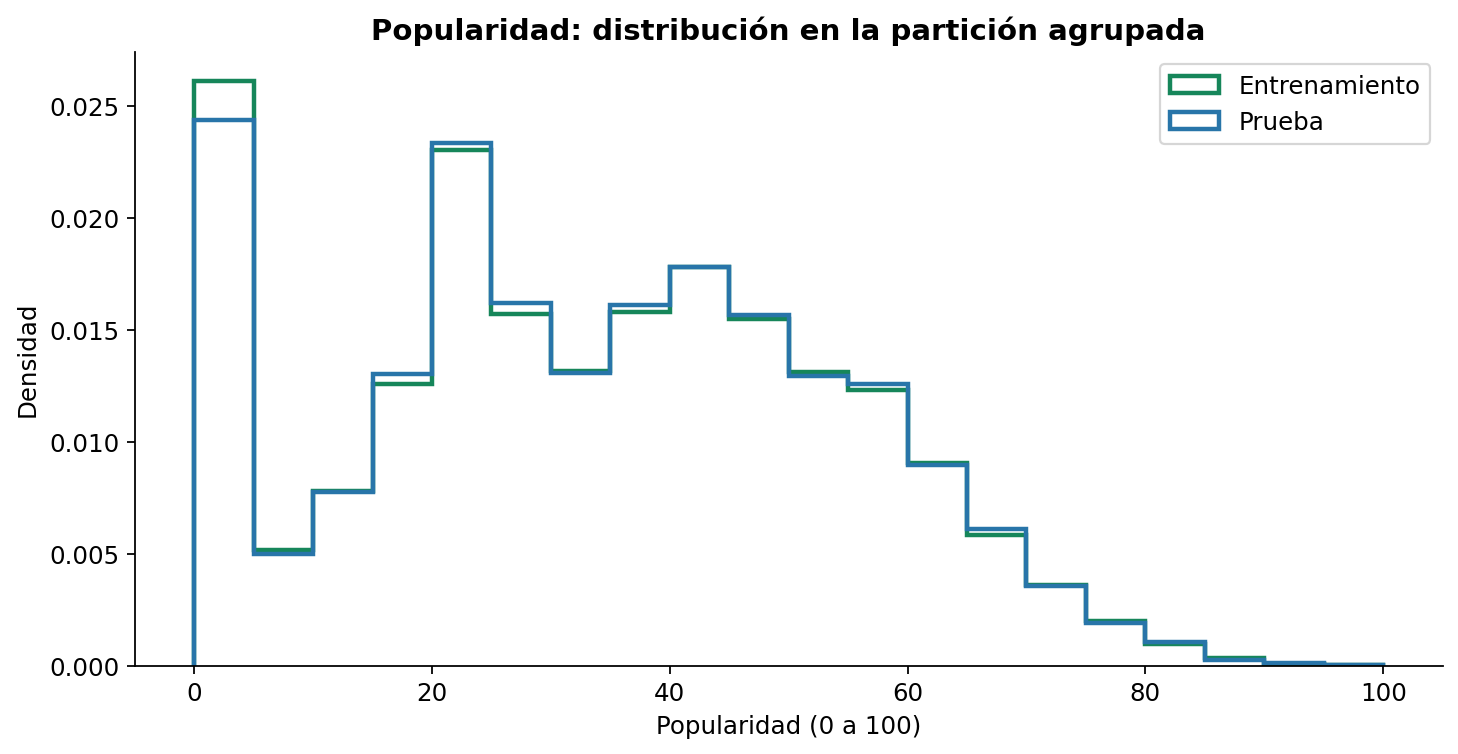

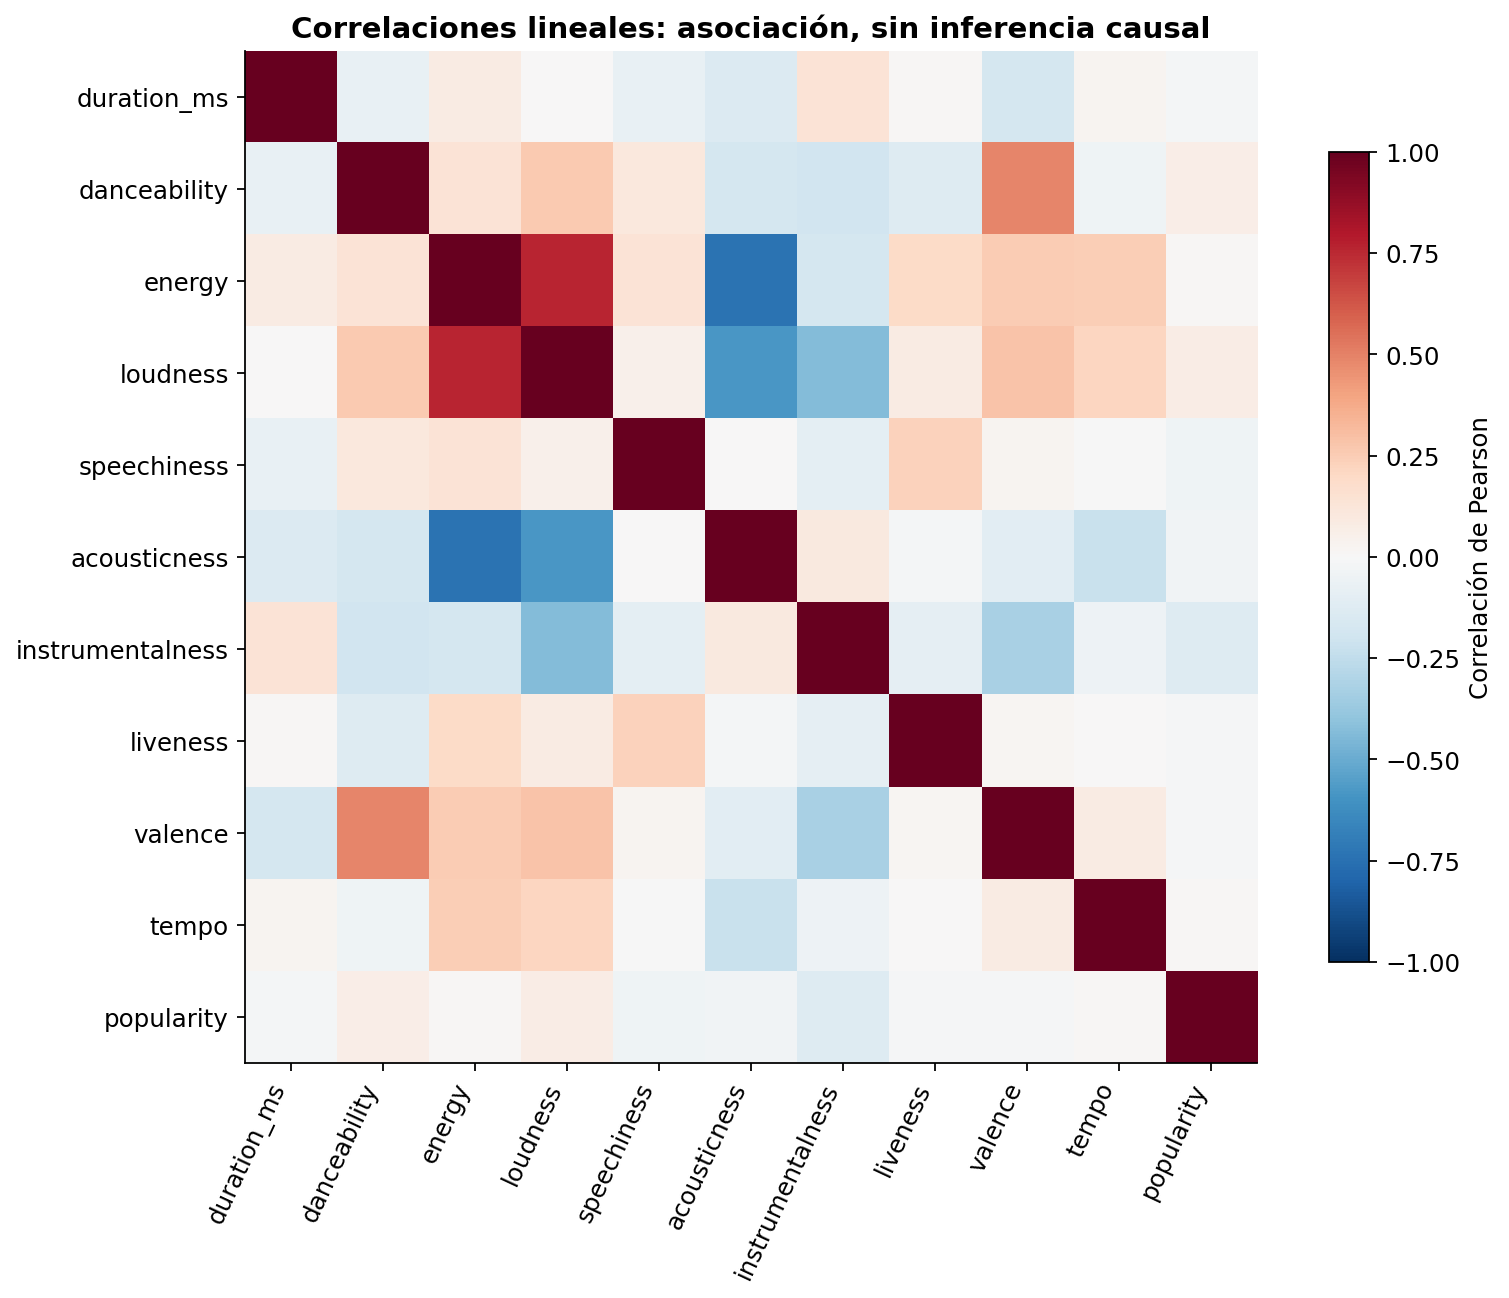

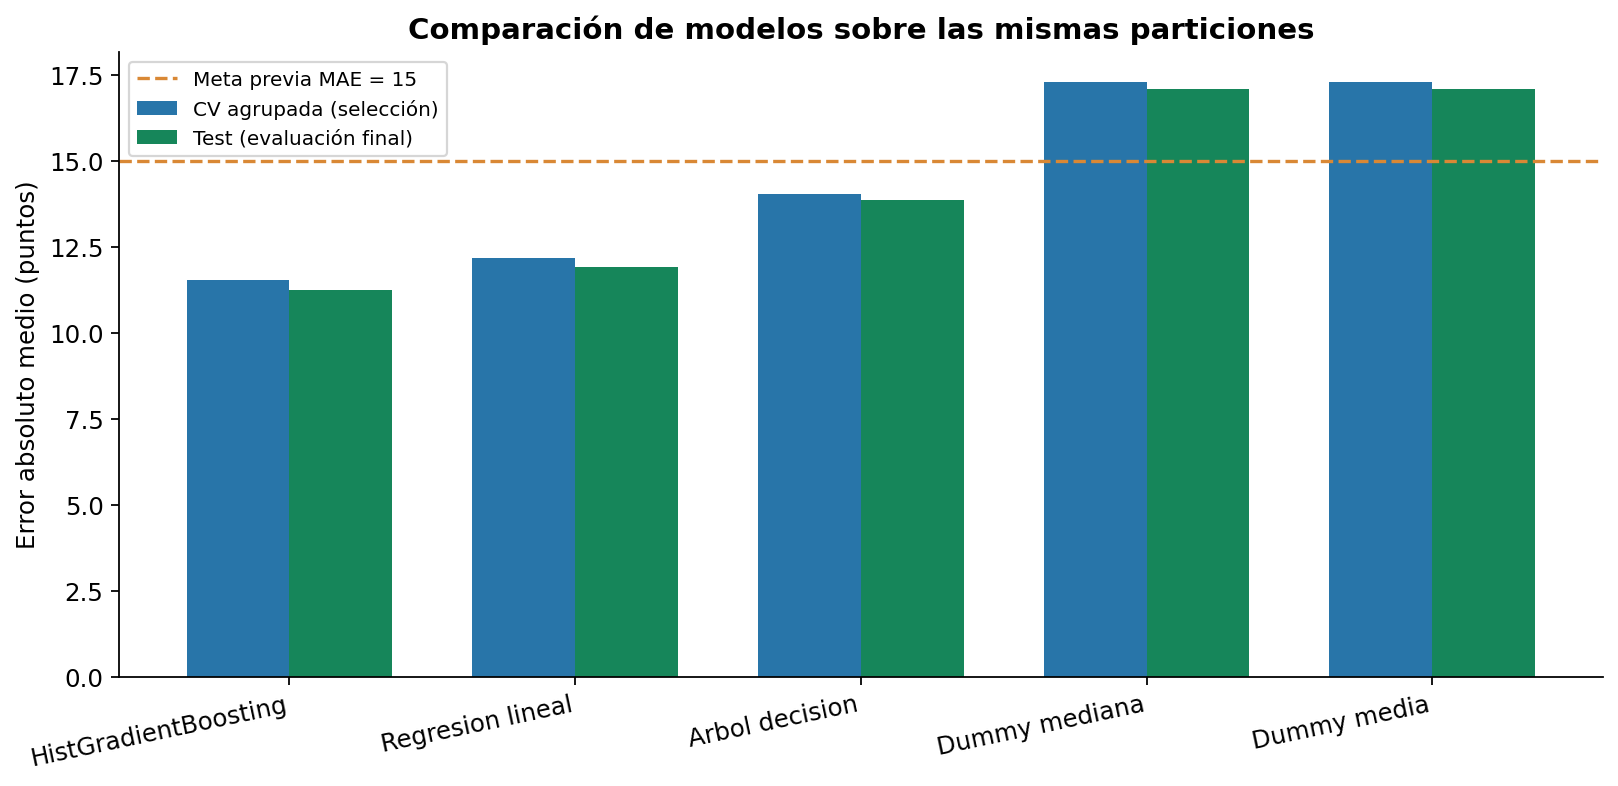

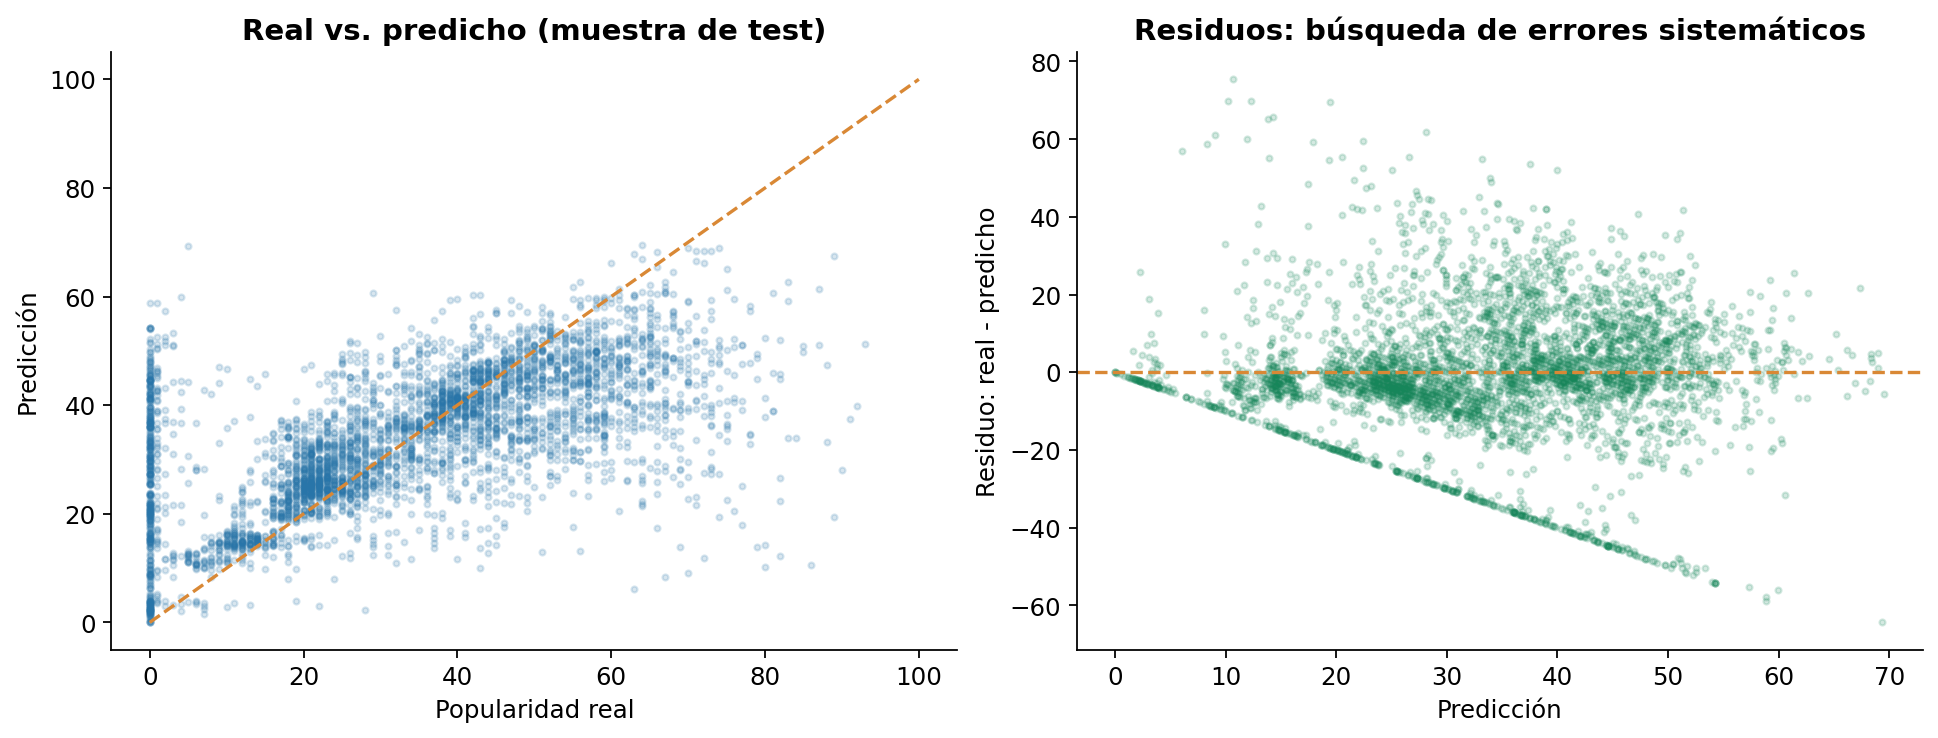

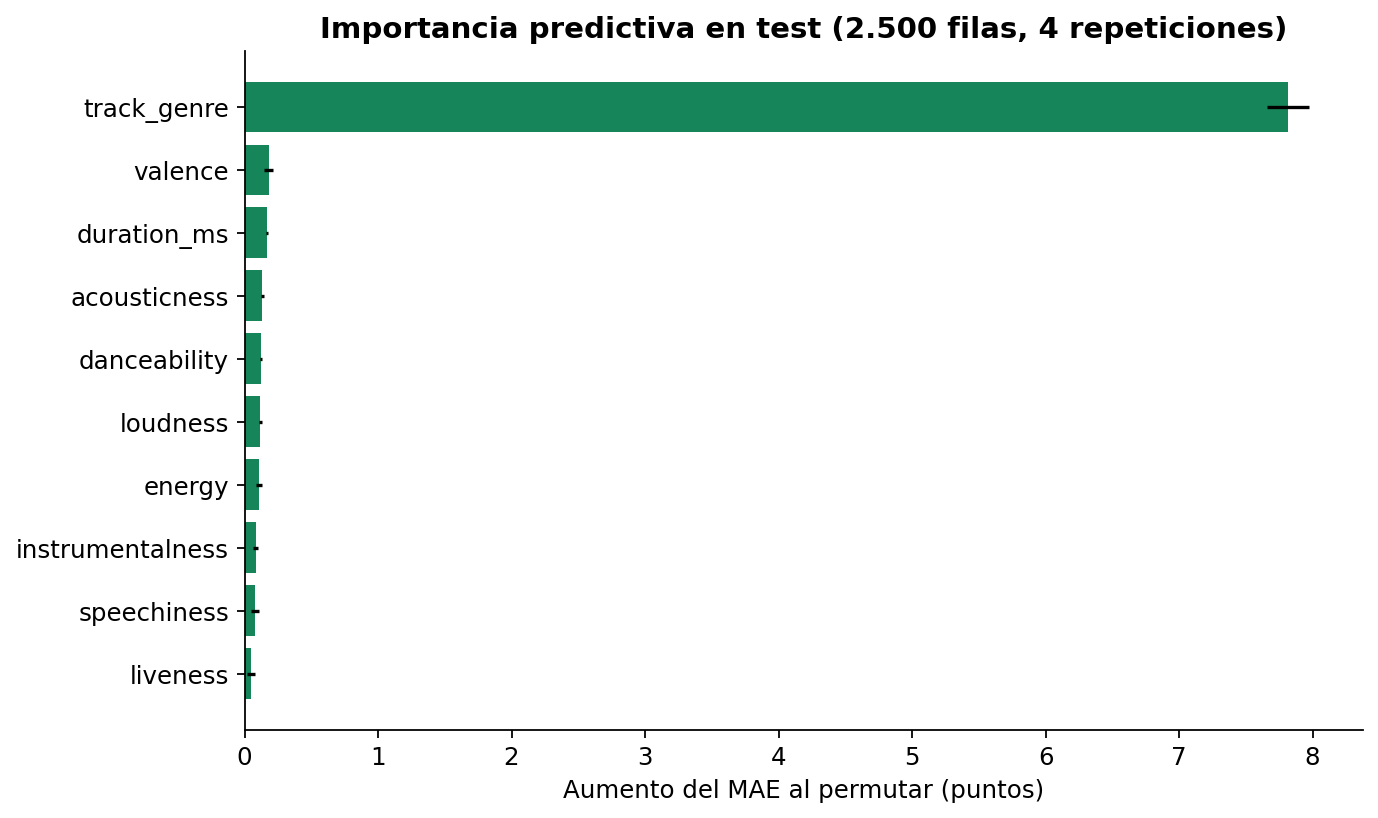

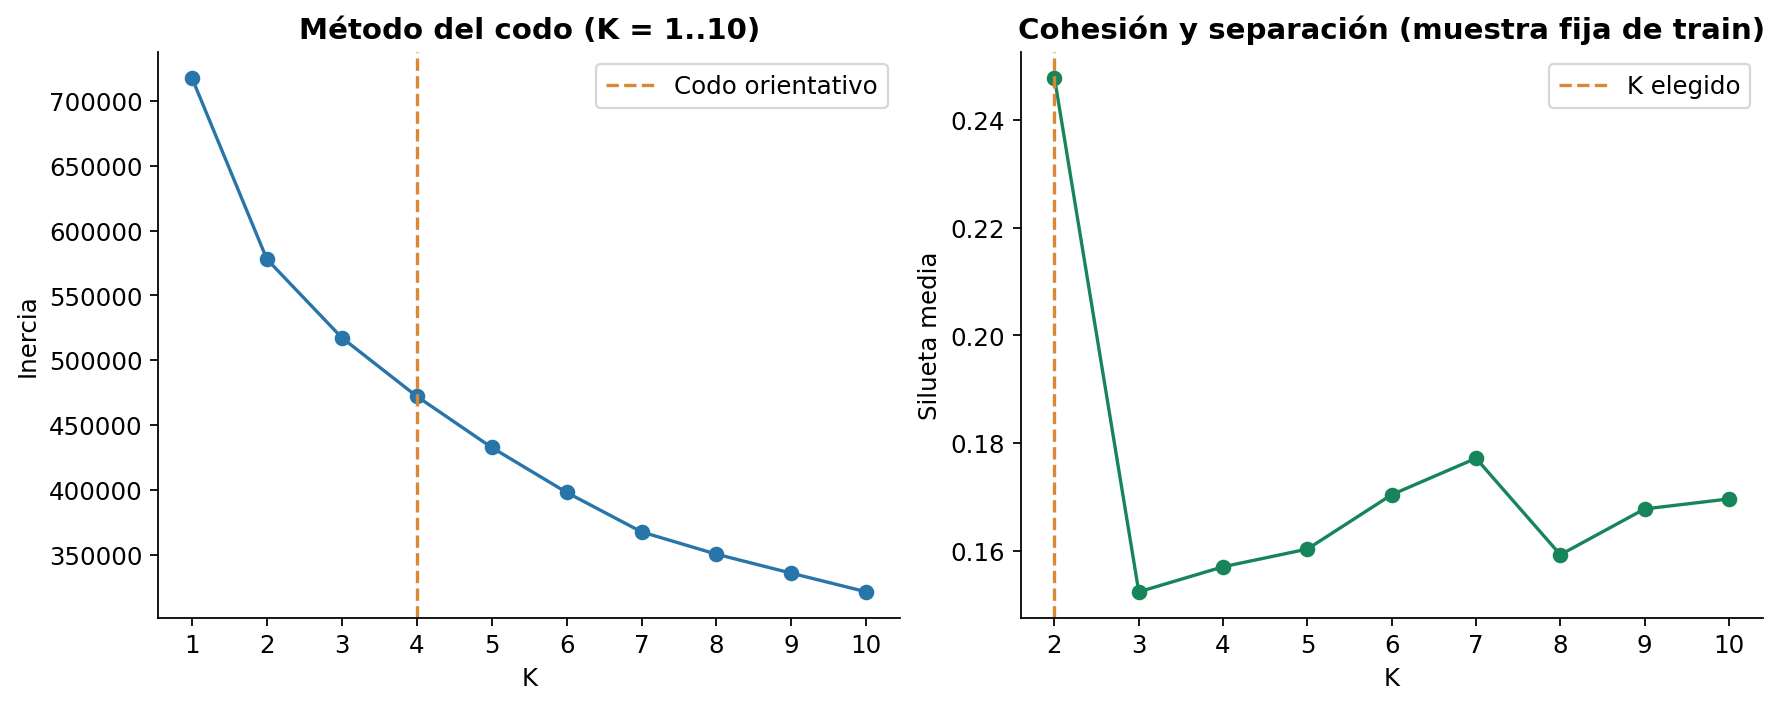

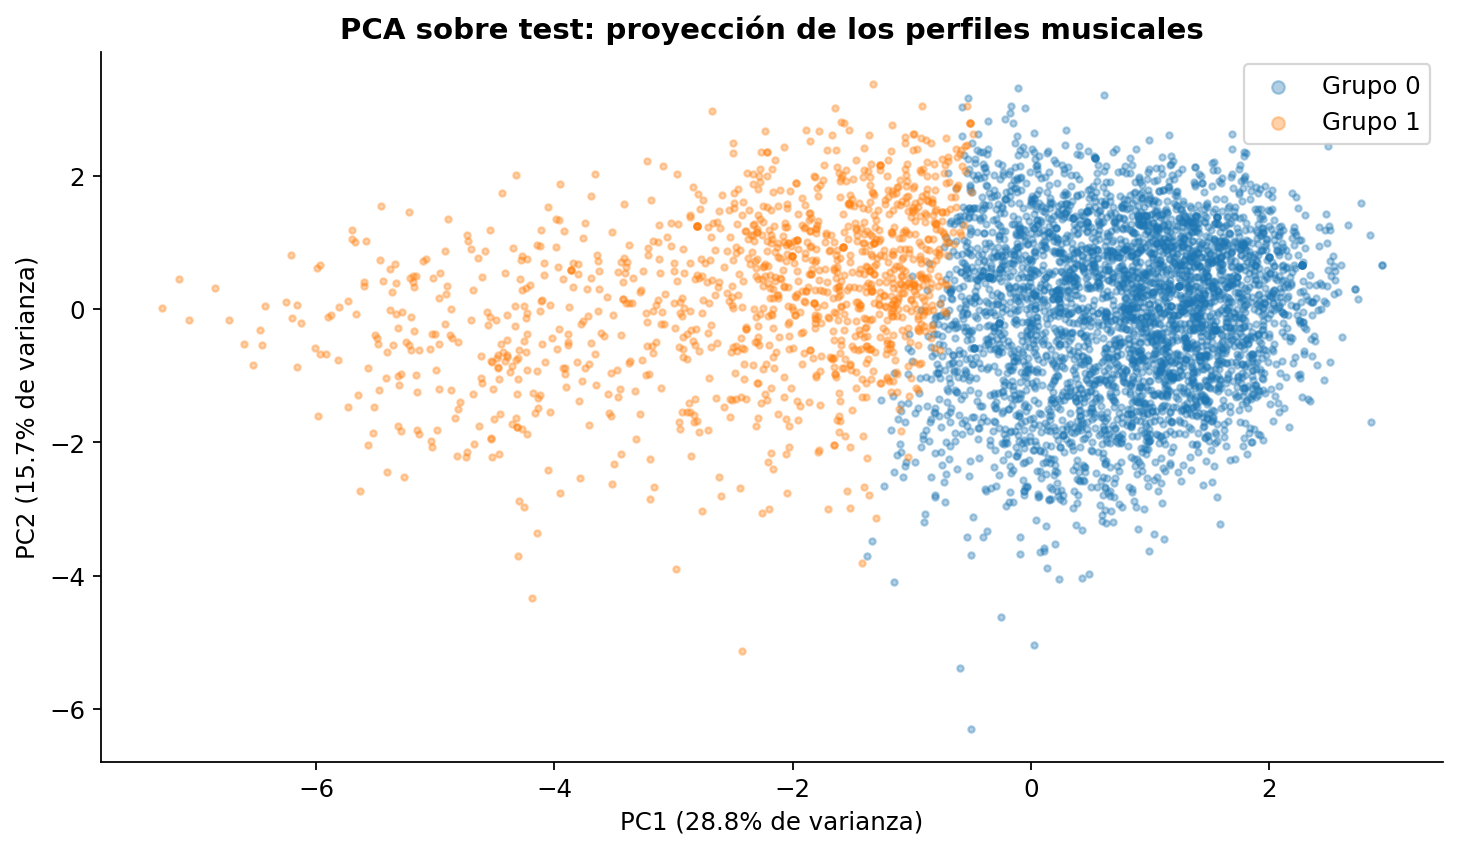

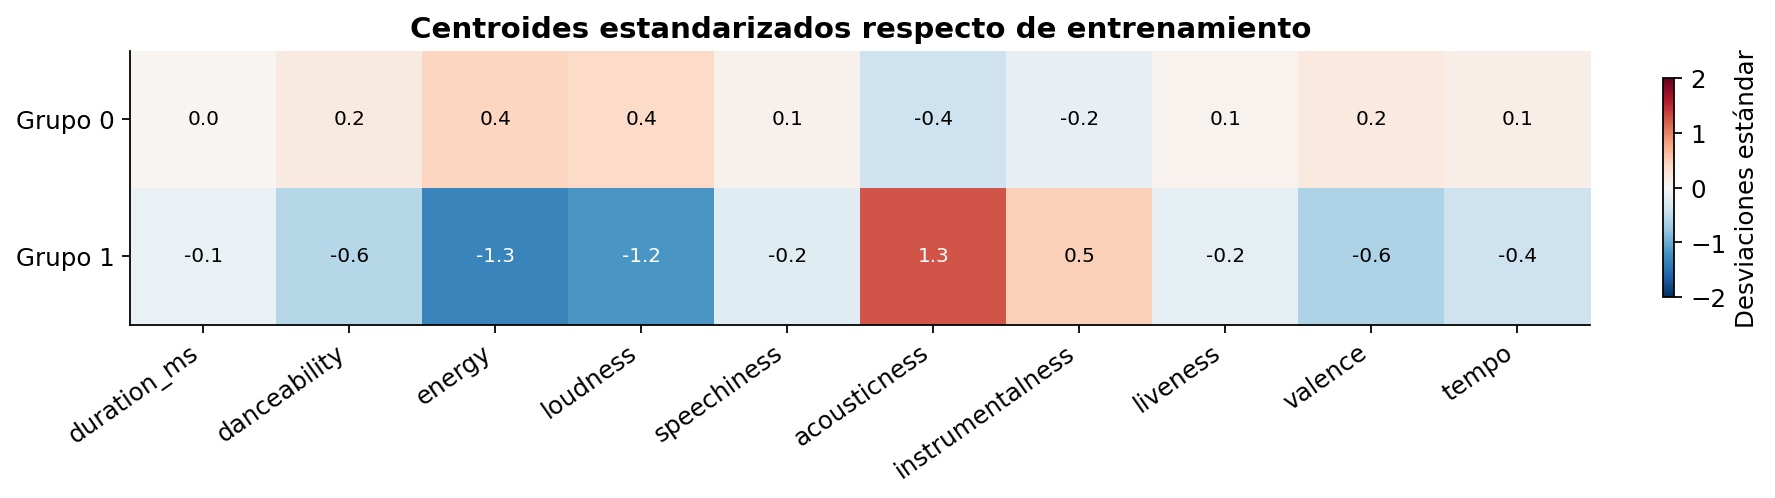

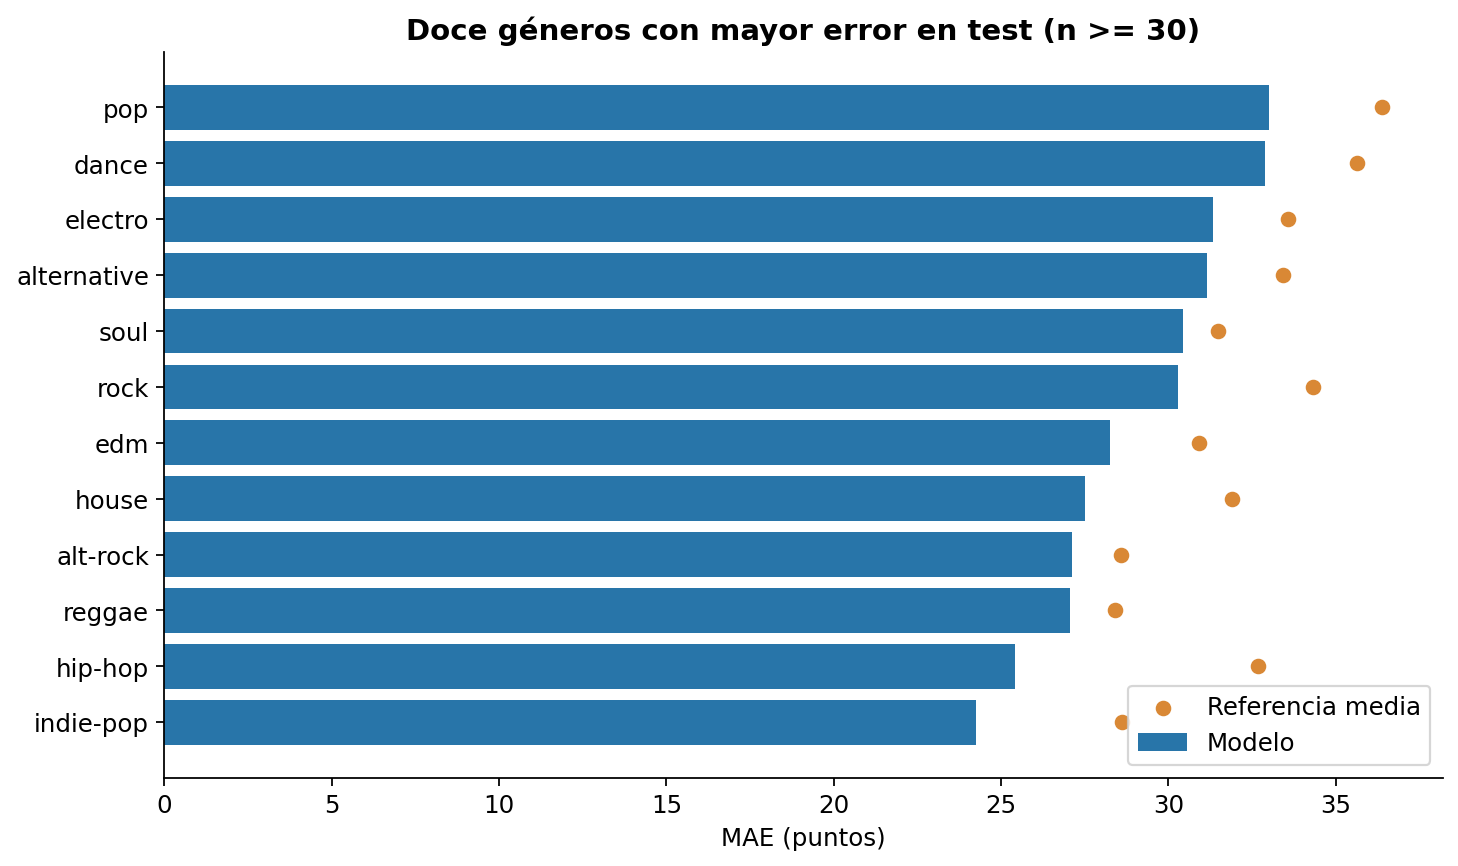

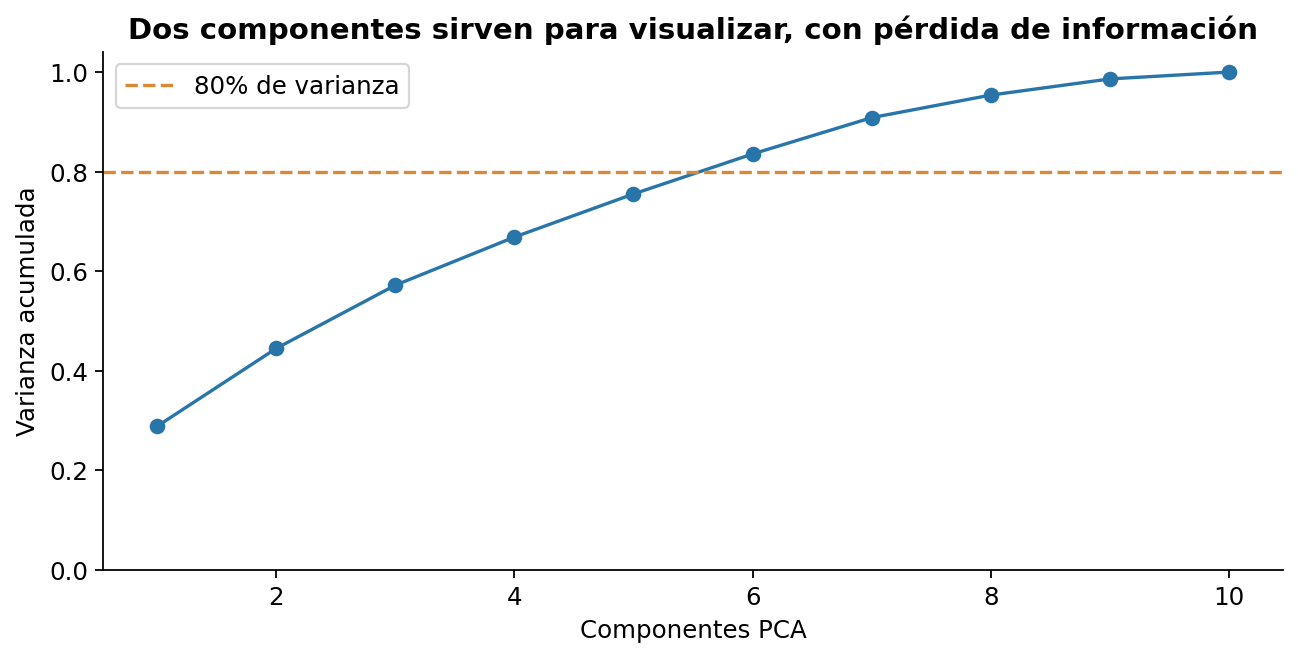

In [8]:
make_plots(data, ROOT)
for name in ['01_popularity.png', '02_correlations.png', '03_model_comparison.png',
             '04_residuals.png', '05_importance.png', '06_k_selection.png',
             '07_pca_clusters.png', '08_cluster_profiles.png',
             '09_subgroups.png', '10_pca_variance.png']:
    display(Image(filename=str(ROOT / 'images/eva2' / name), width=850))

## 6. Inferencia local y conclusiones

Creamos una entrada de tres canciones de test sin el objetivo real. La inferencia valida las 15 variables y usa el pipeline persistido. Esta demostración comprueba el funcionamiento de entrada/salida y no es una nueva validación independiente.

Uso recomendado: exploración con revisión humana. Popularidad no equivale a mérito. Faltan fechas, contexto promocional y muestreo representativo. No se justifican decisiones automáticas de inversión. Las métricas, los errores y la discrepancia entre codo y silueta delimitan este uso.

In [9]:
example = data['clean'].iloc[data['test_idx'][:3]][['track_id'] + MODEL_FEATURES]
(ROOT / 'data/examples').mkdir(exist_ok=True)
example.to_csv(ROOT / 'data/examples/tracks_example.csv', index=False)
example_result = predict(example, ROOT)
example_result.to_csv(ROOT / 'reports/eva2/example_predictions.csv', index=False)
display(example_result)
paths = build_reports(ROOT)
print('Tiempo de cómputo del cuaderno (s):', round(time.perf_counter() - start, 2))
print('Informes actualizados:', {name: path.relative_to(ROOT).as_posix() for name, path in paths.items()})
display(Markdown((ROOT / 'docs/informe_ejecutivo.md').read_text(encoding='utf-8')))

,track_id,predicted_popularity,unknown_genre
0,5SuOikwiRyPMVoIQDJUgSV,36.223786,False
2,1iJBSr7s7jYXzM8EGcbK5b,47.767446,False
6,6Vc5wAMmXdKIAM7WUoEb7N,47.788312,False


Tiempo de cómputo del cuaderno (s): 182.56
Informes actualizados: {'technical': 'docs/informe_tecnico_eva2.md', 'executive': 'docs/informe_ejecutivo.md'}


# Informe ejecutivo - Inteligencia musical en Spotify

**Evaluación Parcial N°2, MLY1101. Caso C. Continuación de experiencia 1.**

Equipo: Benjamín Palomino, Benjamín Díaz y Freymuth Christopher Isaac.

## Decisión que apoya el proyecto

Un equipo de curaduría necesita explorar su catálogo y estimar la popularidad observada de canciones mediante sus características de audio y género. Proponemos una herramienta de consulta local con revisión humana. El dataset es una instantánea sin fecha de extracción confirmada: el proyecto no demuestra que pueda anticipar futuros éxitos.

## Evidencia principal

El CSV recibido contiene 114,000 filas y 89,741 IDs únicos. La limpieza de experiencia 1 deja 89,495 canciones, retiene 99.73% de los IDs originales y no deja nulos. Detectamos además 6,213 filas con audio idéntico a otras de diferente ID. Para evitar contaminación entre entrenamiento y prueba, estas versiones permanecen en el mismo conjunto.

Reservamos 17,715 canciones (19.79%) para prueba y seleccionamos el modelo mediante validación cruzada agrupada de tres folds en las 71,780 restantes. Comparamos dos referencias constantes y tres modelos supervisados: regresión lineal, árbol de decisión y HistGradientBoosting.

El modelo seleccionado, **HistGradientBoosting**, obtiene **MAE 11.24 puntos**, RMSE 16.23 y R² 0.369 en prueba. Reduce el MAE en **34.19%** frente a la media constante (17.08). Cumple las metas previas MAE <= 15 y mejora >= 10%. El IC bootstrap agrupado del MAE es [10.99, 11.46], condicionado a esta prueba y a este modelo.

La comparación más exigente usa la media de popularidad por género calculada solo en entrenamiento: MAE 11.93. Frente a ella, la mejora del modelo completo es **5.74%**. La ablación que retira únicamente género, conservando las otras catorce variables e hiperparámetros, registra MAE 15.28. Esta evidencia indica una dependencia importante del género, sin demostrar un efecto causal del sonido.

La auditoría encontró 720 IDs con distintas popularidades entre filas originales (0.80% de IDs); la diferencia mediana es 1 punto y la máxima 44. Se mantiene la primera observación como referencia reproducible por continuidad y falta de fechas autoritativas. Entrenar con mediana cambia el MAE de CV de 11.519 a 11.530, sin modificar etiquetas de test ni la selección. La incertidumbre de esas etiquetas sigue declarada.

## Segmentación para curaduría

K-Means usa diez variables continuas de audio escaladas, excluye popularidad y género, y compara K=1..10. Se elige K=2 por la mayor silueta entre soluciones con grupos de al menos 3% del entrenamiento. El codo orientativo sugiere K=4, así que no existe un único óptimo respaldado por ambos criterios.

- Grupo 0: 75.3% del entrenamiento, energía 0.75, acústica 0.19 y tempo 126.2. Perfil relativamente energético para explorar selecciones de actividad.
- Grupo 1: 24.7%, energía 0.30, acústica 0.76 y tempo 109.9. Perfil relativamente acústico para explorar selecciones tranquilas.

Son nombres interpretativos, no etiquetas musicales verificadas. La silueta de prueba es 0.237, compatible con separación limitada. Las semillas alternativas dan ARI entre 0.997 y 0.997. PCA en dos dimensiones conserva 44.4% de varianza: sirve como mapa parcial, no como demostración de grupos perfectamente separados.

## Recomendación y límites

Recomendamos un piloto de exploración de catálogo con evaluación humana. No automatizar contratos ni presupuestos de promoción. El MAE para canciones de popularidad 81-100 es 44.91 en solo 105 casos: el modelo subestima los extremos. El percentil 95 del error absoluto es 37.30 puntos.

No se puede calcular ROI con estos datos: faltan costos, resultados de campañas y una evaluación causal. El [piloto propuesto](plan_piloto_negocio.md), aún no ejecutado, fija dos semanas y tres metas sujetas a aprobación: reducción mediana del tiempo >=15%, aceptación de recomendaciones >=70% y pérdida mediana de cobertura de géneros no mayor a 5 puntos porcentuales. Define fórmulas, responsables, doce pares de sesiones exploratorios y una plantilla vacía con calculadora validada. Antes de uso real se requiere una muestra reciente, evaluación temporal, revisión de la etiqueta género y validación de derechos de uso.

El desarrollo completo, fórmulas, decisiones, riesgos y matriz de rúbrica están en [informe técnico](informe_tecnico_eva2.md). El [notebook integral](../notebooks/05_proyecto_completo_eva2.ipynb) reproduce las etapas desde el CSV original.


## 7. KPIs de negocio y piloto propuesto

El piloto no se ha ejecutado. El plan propone dos semanas y doce pares exploratorios, con metas sujetas a aprobación de curaduría: reducción mediana del tiempo por par >=15%, aceptación agregada >=70% y delta mediano de cobertura de géneros >=-5 pp. Define responsables, condiciones comparables y reglas para continuar, ajustar o detener. Son objetivos de validación, no beneficios comerciales medidos.

La calculadora `src/eva2/pilot.py` usa tiempos normalizados por 100 canciones, aceptación como razón de sumas y cobertura según géneros disponibles/cupos. Sus pruebas son sintéticas. Ver `docs/plan_piloto_negocio.md`. La plantilla siguiente debe permanecer vacía hasta recoger sesiones reales.

In [10]:
from src.eva2.pilot import pilot_metrics
pilot_template = pd.read_csv(ROOT / 'data/examples/pilot_template.csv')
display(pilot_template)
assert pilot_template.empty
try:
    pilot_metrics(pilot_template)
except ValueError as error:
    print('Control esperado, sin inventar mediciones:', error)

,reviewer_alias,pair_id,method,reviewed_tracks,selected_tracks,duration_seconds,recommended_tracks,accepted_recommendations,selected_genres,available_genres


Control esperado, sin inventar mediciones: Plantilla vacía: no hay piloto ejecutado ni resultados comerciales que calcular


## Fuentes y reproducción

Pauta y ocho PDF de clases entregados por el equipo, experiencia 1 y documentación primaria de scikit-learn. Referencias, enlaces y limitaciones de procedencia en `docs/fuentes_eva2.md`. El informe técnico contiene la matriz IE5/IE6/IE7/IE8 y las fórmulas.

Para verificar desde terminal: `python -m unittest discover -s tests -v` y `python scripts/verify_delivery.py`. La evidencia efectiva queda en `reports/eva2/verification.json`. No se asigna una calificación automáticamente.